# IDA117V Group Project – Johannesburg Water Outage Early-Warning
Reproducible code for Questions 1–8. **Run all cells top to bottom** (seed 42; about 3–5 minutes).
Set `DATA_PATH` in the first code cell to your copy of `johannesburg_water_outage_synthetic.csv`.
The dataset is **synthetic**: replace it with the approved real dataset before final submission.

| Section | Question |
|---|---|
| 1 | Q2.1 Data audit |
| 2 | Q2.2 Visualisations |
| 3 | Q2.3–2.4 Split and preprocessing pipeline |
| 4 | Q3–Q4 Baseline, models, evaluation, overfitting |
| 5 | Q5 Hyperparameter optimisation |
| 6 | Q6 Ablation study and McNemar test |
| 7 | Q5.3 / Q8 Final test, fairness, saved pipeline |
| 8 | Q7 Streamlit interface and tests |

In [ ]:
import os, json, itertools, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import binomtest
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report, roc_curve)
warnings.filterwarnings('ignore')

# ---------------- CONFIG ----------------
DATA_PATH = 'johannesburg_water_outage_synthetic.csv'
if not os.path.exists(DATA_PATH): DATA_PATH = './johannesburg_water_outage_synthetic 1.csv'
SEED = 42
os.makedirs('figures', exist_ok=True)
np.random.seed(SEED)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORG = '#2F5597', '#C55A11'
print('pandas', pd.__version__)

pandas 3.0.3


## 1. Data audit (Q2.1)

In [5]:
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape, '| wards:', raw.ward_id.nunique(), '| periods:', raw.period_index.min(), '-', raw.period_index.max())
print('\nClass balance:\n', raw.outage_risk.value_counts())
print('\nMissing values:\n', raw.isna().sum()[raw.isna().sum() > 0])
print('\nDuplicate rows:', raw.duplicated().sum())
print('Negative pipe ages:', (raw.pipe_age_years < 0).sum(), '| pressure == 999 (sensor code):', (raw.avg_pressure_kpa == 999).sum())

num_aud = ['pipe_age_years','avg_pressure_kpa','reservoir_distance_km','elevation_m','recent_complaints','rainfall_mm','max_temp_c','informal_settlement_pct']
rows = []
for c in num_aud:
    s = raw[c].dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    rows.append((c, int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())))
print('\nIQR outlier counts:', dict(rows))

# Leakage check: columns recorded AFTER the event
y_raw = (raw.outage_risk == 'high').astype(int)
print('\nCorrelation with target ->', {c: round(raw[c].corr(y_raw), 2) for c in ['repair_cost_zar', 'emergency_dispatches']})
raw.describe().T.round(2)

Shape: (3545, 19) | wards: 135 | periods: 1 - 26

Class balance:
 outage_risk
low     3009
high     536
Name: count, dtype: int64

Missing values:
 avg_pressure_kpa    192
elevation_m          72
dtype: int64

Duplicate rows: 35
Negative pipe ages: 15 | pressure == 999 (sensor code): 12

IQR outlier counts: {'pipe_age_years': 14, 'avg_pressure_kpa': 31, 'reservoir_distance_km': 211, 'elevation_m': 78, 'recent_complaints': 160, 'rainfall_mm': 233, 'max_temp_c': 0, 'informal_settlement_pct': 340}

Correlation with target -> {'repair_cost_zar': np.float64(0.85), 'emergency_dispatches': np.float64(0.83)}


,count,mean,std,min,25%,50%,75%,max
latitude,3545.0,-26.16,0.13,-26.48,-26.26,-26.14,-26.08,-25.90
longitude,3545.0,27.97,0.10,27.78,27.88,28.00,28.05,28.14
period_index,3545.0,13.49,7.50,1.00,7.00,13.00,20.00,26.00
pipe_age_years,3545.0,33.29,14.44,-61.60,23.40,33.30,43.70,62.30
avg_pressure_kpa,3353.0,358.42,65.52,0.00,322.50,354.50,390.20,999.00
reservoir_distance_km,3545.0,4.69,2.79,0.46,2.60,4.28,5.75,19.13
elevation_m,3473.0,1649.84,55.95,1480.00,1618.00,1656.00,1687.00,1797.00
recent_complaints,3545.0,2.51,2.62,0.00,1.00,2.00,4.00,18.00
rainfall_mm,3545.0,9.85,9.41,0.00,3.70,7.10,12.70,83.30
max_temp_c,3545.0,22.01,5.16,10.20,17.30,22.00,26.80,32.80


In [6]:
# Row-level, rule-based cleaning only (no learned statistics, so safe before splitting)
df = raw.drop_duplicates().copy()
df.loc[df.pipe_age_years < 0, 'pipe_age_years'] = np.nan
df.loc[df.avg_pressure_kpa >= 999, 'avg_pressure_kpa'] = np.nan
df['y'] = (df.outage_risk == 'high').astype(int)
df['period_start'] = pd.to_datetime(df.period_start)
print('Clean rows:', len(df), '| high-risk share: %.1f%%' % (df.y.mean()*100))

Clean rows: 3510 | high-risk share: 15.0%


## 2. Visualisations (Q2.2)

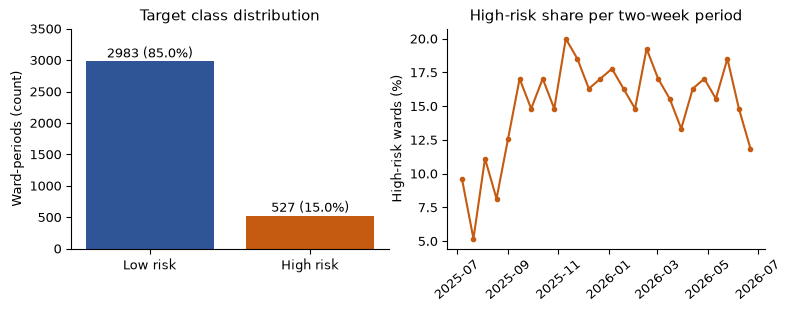

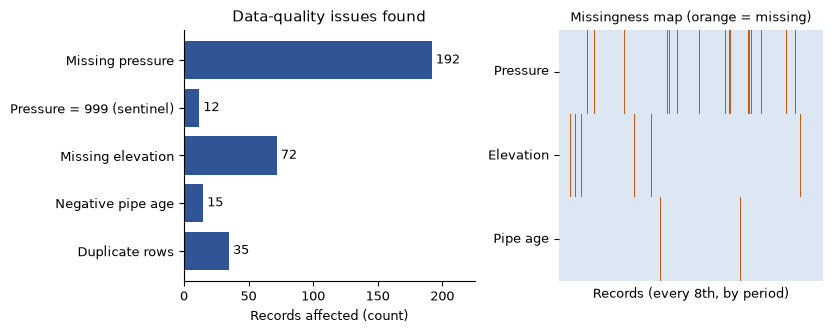

In [7]:
# Fig 1: target distribution + time trend
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
vc = df.outage_risk.value_counts().reindex(['low', 'high'])
ax[0].bar(['Low risk', 'High risk'], vc.values, color=[BLUE, ORG]); ax[0].set_ylim(0, 3500)
ax[0].set_ylabel('Ward-periods (count)'); ax[0].set_title('Target class distribution')
for i, v in enumerate(vc.values): ax[0].text(i, v+60, f'{v} ({v/len(df):.1%})', ha='center')
t = df.groupby('period_start').y.mean()*100
ax[1].plot(t.index, t.values, color=ORG, marker='o', ms=3); ax[1].tick_params(axis='x', rotation=40)
ax[1].set_ylabel('High-risk wards (%)'); ax[1].set_title('High-risk share per two-week period')
plt.tight_layout(); plt.savefig('figures/f1_target.png', dpi=180); plt.show()

# Fig 2: data quality + missingness map
fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.4), gridspec_kw={'width_ratios': [1.1, 1]})
bad = pd.Series({'Missing pressure': raw.avg_pressure_kpa.isna().sum(), 'Pressure = 999 (sentinel)': (raw.avg_pressure_kpa == 999).sum(),
                 'Missing elevation': raw.elevation_m.isna().sum(), 'Negative pipe age': (raw.pipe_age_years < 0).sum(), 'Duplicate rows': raw.duplicated().sum()})
ax[0].barh(bad.index[::-1], bad.values[::-1], color=BLUE); ax[0].set_xlim(0, 225)
ax[0].set_xlabel('Records affected (count)'); ax[0].set_title('Data-quality issues found')
for i, v in enumerate(bad.values[::-1]): ax[0].text(v+3, i, str(v), va='center')
sns.heatmap(df.sort_values('period_index')[['avg_pressure_kpa', 'elevation_m', 'pipe_age_years']].isna().T.iloc[:, ::8].astype(int),
            cmap=['#DDE6F3', ORG], cbar=False, ax=ax[1], xticklabels=False)
ax[1].set_yticklabels(['Pressure', 'Elevation', 'Pipe age'], rotation=0)
ax[1].set_title('Missingness map (orange = missing)', fontsize=9); ax[1].set_xlabel('Records (every 8th, by period)')
plt.tight_layout(); plt.savefig('figures/f2_quality.png', dpi=180); plt.show()

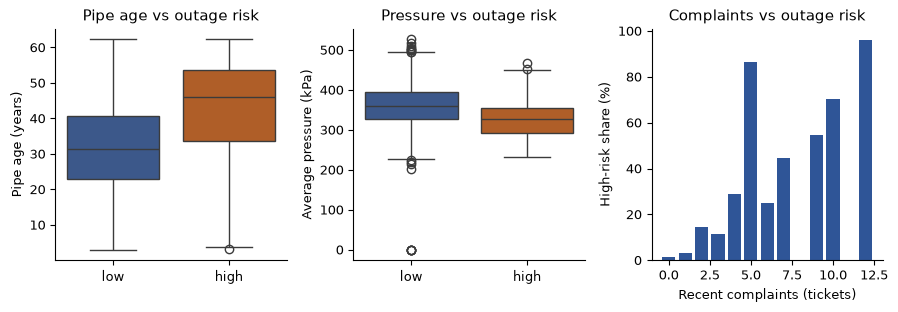

             pipe_age_years  avg_pressure_kpa  recent_complaints
outage_risk                                                     
high                   46.1            327.45                4.0
low                    31.3            359.60                1.0


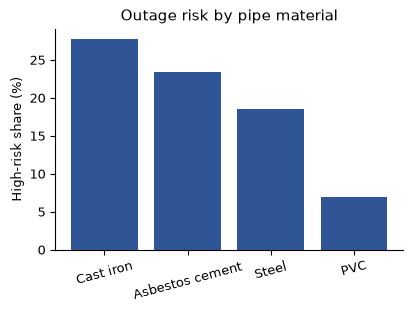

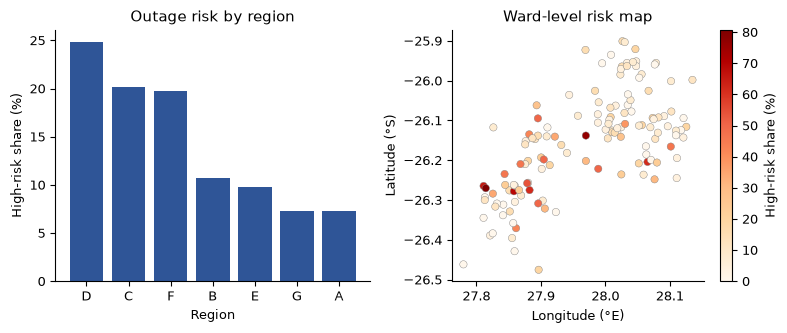

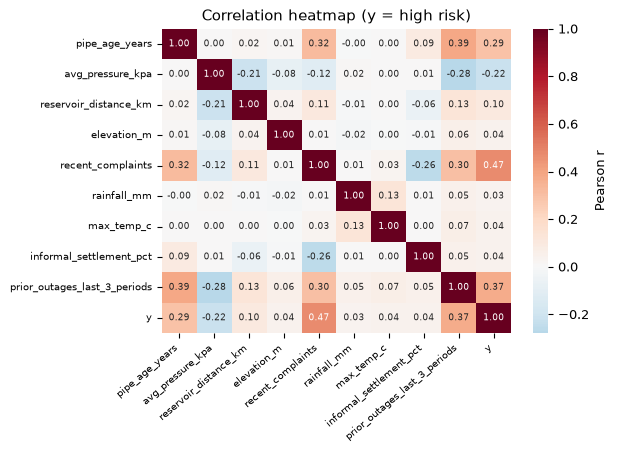

In [8]:
# Fig 3: feature-target relationships
fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
sns.boxplot(data=df, x='outage_risk', y='pipe_age_years', order=['low', 'high'], palette=[BLUE, ORG], ax=ax[0]); ax[0].set(ylabel='Pipe age (years)', xlabel='', title='Pipe age vs outage risk')
sns.boxplot(data=df, x='outage_risk', y='avg_pressure_kpa', order=['low', 'high'], palette=[BLUE, ORG], ax=ax[1]); ax[1].set(ylabel='Average pressure (kPa)', xlabel='', title='Pressure vs outage risk')
g = df.groupby('recent_complaints').y.agg(['mean', 'size']); g = g[g['size'] >= 10]
ax[2].bar(g.index, g['mean']*100, color=BLUE); ax[2].set(xlabel='Recent complaints (tickets)', ylabel='High-risk share (%)', title='Complaints vs outage risk')
plt.tight_layout(); plt.savefig('figures/f3_features.png', dpi=180); plt.show()
print(df.groupby('outage_risk')[['pipe_age_years', 'avg_pressure_kpa', 'recent_complaints']].median())

# Fig 4/5: material and region/map
mt = (df.groupby('pipe_material').y.mean()*100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(4.2, 3.2)); ax.bar(mt.index, mt.values, color=BLUE)
ax.set(ylabel='High-risk share (%)', title='Outage risk by pipe material'); plt.xticks(rotation=15); plt.tight_layout()
plt.savefig('figures/f5_material.png', dpi=180); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
r = df.groupby('region').y.mean().sort_values(ascending=False)*100
ax[0].bar(r.index, r.values, color=BLUE); ax[0].set(xlabel='Region', ylabel='High-risk share (%)', title='Outage risk by region')
w = df.groupby('ward_id').agg(lat=('latitude', 'first'), lon=('longitude', 'first'), rate=('y', 'mean'))
sc = ax[1].scatter(w.lon, w.lat, c=w.rate*100, cmap='OrRd', s=28, edgecolor='grey', linewidth=.3)
plt.colorbar(sc, ax=ax[1], label='High-risk share (%)'); ax[1].set(xlabel='Longitude (°E)', ylabel='Latitude (°S)', title='Ward-level risk map')
plt.tight_layout(); plt.savefig('figures/f4_geo.png', dpi=180); plt.show()

# Fig 6: correlation heatmap
cols = ['pipe_age_years', 'avg_pressure_kpa', 'reservoir_distance_km', 'elevation_m', 'recent_complaints', 'rainfall_mm', 'max_temp_c', 'informal_settlement_pct', 'prior_outages_last_3_periods', 'y']
fig, ax = plt.subplots(figsize=(6.2, 4.6))
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, annot_kws={'size': 6.5}, cbar_kws={'label': 'Pearson r'})
ax.set_title('Correlation heatmap (y = high risk)'); plt.xticks(rotation=40, ha='right', fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); plt.savefig('figures/f6_corr.png', dpi=180); plt.show()

## 3. Split before learning (Q2.3) and preprocessing pipeline (Q2.4)
Time-ordered split: train = periods 1–16, validation = 17–21, test = 22–26 (locked until section 7).
`repair_cost_zar`, `emergency_dispatches` (post-event leakage), `ward_id`, coordinates and dates are **not** model inputs.

In [10]:
NUM_BASE = ['pipe_age_years', 'avg_pressure_kpa', 'reservoir_distance_km', 'elevation_m', 'recent_complaints',
            'rainfall_mm', 'max_temp_c', 'informal_settlement_pct', 'prior_outages_last_3_periods']
CAT = ['pipe_material', 'region']
# Engineered feature: old pipes under low pressure. Row-wise only (fixed 350 kPa fill) so no statistics are learned before the split.
df['age_x_lowpressure'] = df.pipe_age_years / (df.avg_pressure_kpa.fillna(350).clip(lower=50) / 100)
NUM = NUM_BASE + ['age_x_lowpressure']; FEATS = NUM + CAT

tr = df[df.period_index <= 16]; va = df[(df.period_index >= 17) & (df.period_index <= 21)]; te = df[df.period_index >= 22]
print(pd.DataFrame({'rows': [len(tr), len(va), len(te)], 'high_risk': [tr.y.sum(), va.y.sum(), te.y.sum()],
                    'share_%': [round(d.y.mean()*100, 1) for d in (tr, va, te)]}, index=['train (1-16)', 'val (17-21)', 'test (22-26)']))
Xtr, ytr, Xva, yva, Xte, yte = tr[FEATS], tr.y, va[FEATS], va.y, te[FEATS], te.y

def make_pre(num=NUM, cat=CAT):
    t = [('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num)]
    if cat: t.append(('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat))
    return ColumnTransformer(t)

def oversample(X, y, seed=SEED):
    # random oversampling of the minority class - applied to TRAINING data only
    rng = np.random.RandomState(seed); i1 = np.where(y.values == 1)[0]; i0 = np.where(y.values == 0)[0]
    i = np.concatenate([i0, i1, rng.choice(i1, len(i0)-len(i1), replace=True)]); rng.shuffle(i)
    return X.iloc[i], y.iloc[i]

              rows  high_risk  share_%
train (1-16)  2160        312     14.4
val (17-21)    675        110     16.3
test (22-26)   675        105     15.6


## 4. Baseline, models and evaluation (Q3–Q4)

In [11]:
models = {
    'Dummy (stratified)': DummyClassifier(strategy='stratified', random_state=SEED),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=SEED),
    'MLP (1 hidden layer)': MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-3, early_stopping=True, validation_fraction=.15, n_iter_no_change=15, max_iter=500, random_state=SEED),
    'Deep MLP (3 hidden layers)': MLPClassifier(hidden_layer_sizes=(64, 32, 16), alpha=1e-2, early_stopping=True, validation_fraction=.15, n_iter_no_change=15, max_iter=500, random_state=SEED),
}
USE_OVERSAMPLING = {'Gradient Boosting'}                         # duplicated minority rows
USE_WEIGHTS = {'MLP (1 hidden layer)', 'Deep MLP (3 hidden layers)'}  # class weights (keeps the internal early-stopping split free of duplicates)

def fit_model(name, model, X, y):
    p = Pipeline([('pre', make_pre()), ('m', clone(model))])
    if name in USE_OVERSAMPLING:
        Xo, yo = oversample(X, y); p.fit(Xo, yo)
    elif name in USE_WEIGHTS:
        w = np.where(y.values == 1, (y == 0).sum()/(y == 1).sum(), 1.0); p.fit(X, y, m__sample_weight=w)
    else:
        p.fit(X, y)
    return p

def metrics(y, pred, prob):
    return dict(acc=accuracy_score(y, pred), prec=precision_score(y, pred, zero_division=0), rec=recall_score(y, pred), f1=f1_score(y, pred),
                macro_f1=f1_score(y, pred, average='macro'), roc_auc=roc_auc_score(y, prob), pr_auc=average_precision_score(y, prob))

fitted, rows = {}, []
for n, m in models.items():
    p = fit_model(n, m, Xtr, ytr); fitted[n] = p
    row = {'model': n, **metrics(yva, p.predict(Xva), p.predict_proba(Xva)[:, 1])}
    row['train_f1'] = f1_score(ytr, p.predict(Xtr)); rows.append(row)
V = pd.DataFrame(rows).set_index('model')
V.round(3)   # Q4.1 - identical held-out (validation) metrics for every model

,acc,prec,rec,f1,macro_f1,roc_auc,pr_auc,train_f1
model,,,,,,,,
Dummy (stratified),0.745,0.202,0.191,0.196,0.522,0.522,0.170,0.123
Logistic Regression,0.833,0.492,0.827,0.617,0.755,0.902,0.707,0.577
Random Forest,0.865,0.604,0.500,0.547,0.734,0.877,0.600,0.904
Gradient Boosting,0.858,0.545,0.764,0.636,0.774,0.896,0.688,0.717
MLP (1 hidden layer),0.816,0.464,0.809,0.589,0.736,0.896,0.693,0.582
Deep MLP (3 hidden layers),0.844,0.514,0.836,0.637,0.769,0.901,0.683,0.667


In [12]:
# Expanding-window cross-validation on training data (variability)
folds = [(8, 11), (11, 14), (14, 16)]
cv = {}
for n in models:
    sc = []
    for a, b in folds:
        t1 = tr[tr.period_index <= a]; t2 = tr[(tr.period_index > a) & (tr.period_index <= b)]
        sc.append(f1_score(t2.y, fit_model(n, models[n], t1[FEATS], t1.y).predict(t2[FEATS])))
    cv[n] = (np.mean(sc), np.std(sc))
CV = pd.DataFrame(cv, index=['cv_f1_mean', 'cv_f1_sd']).T; print(CV.round(3))

# Champion selection rule: highest validation F1; models within 0.01 F1 are tied and the tie is broken by CV F1
cand = V.drop('Dummy (stratified)'); top = cand.f1.idxmax()
tied = [n for n in cand.index if cand.loc[top, 'f1'] - cand.loc[n, 'f1'] <= 0.01]
champ = max(tied, key=lambda n: cv[n][0])
print('\nTop validation F1:', top, '| tied:', tied, '| provisional champion:', champ)

                            cv_f1_mean  cv_f1_sd
Dummy (stratified)               0.136     0.027
Logistic Regression              0.570     0.012
Random Forest                    0.612     0.086
Gradient Boosting                0.674     0.059
MLP (1 hidden layer)             0.513     0.039
Deep MLP (3 hidden layers)       0.541     0.034

Top validation F1: Deep MLP (3 hidden layers) | tied: ['Gradient Boosting', 'Deep MLP (3 hidden layers)'] | provisional champion: Gradient Boosting


===== Dummy (stratified)
              precision    recall  f1-score   support

         low      0.844     0.853     0.849       565
        high      0.202     0.191     0.196       110

    accuracy                          0.745       675
   macro avg      0.523     0.522     0.522       675
weighted avg      0.739     0.745     0.742       675

===== Logistic Regression
              precision    recall  f1-score   support

         low      0.961     0.834     0.893       565
        high      0.492     0.827     0.617       110

    accuracy                          0.833       675
   macro avg      0.727     0.830     0.755       675
weighted avg      0.885     0.833     0.848       675

===== Random Forest
              precision    recall  f1-score   support

         low      0.906     0.936     0.921       565
        high      0.604     0.500     0.547       110

    accuracy                          0.865       675
   macro avg      0.755     0.718     0.734       675
wei

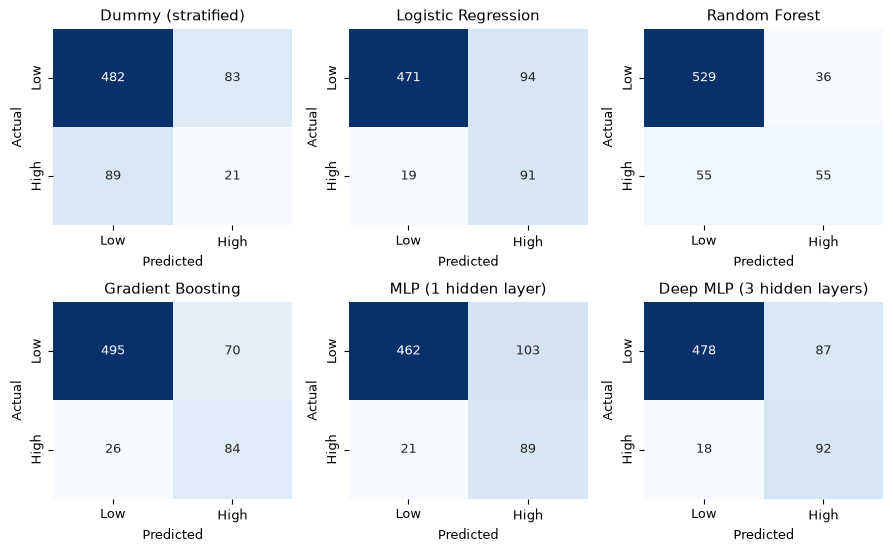

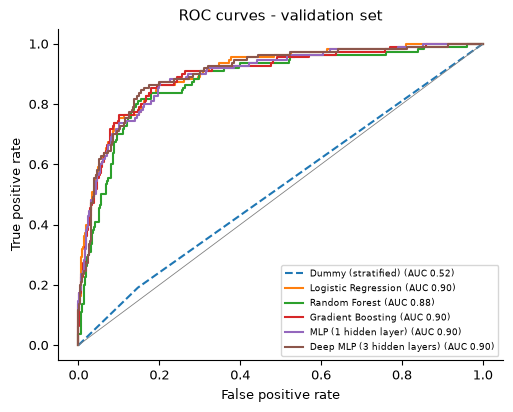

In [13]:
# Q4.2 classification reports + confusion matrices + common ROC figure
for n, p in fitted.items():
    print('=====', n); print(classification_report(yva, p.predict(Xva), target_names=['low', 'high'], zero_division=0, digits=3))

fig, ax = plt.subplots(2, 3, figsize=(9, 5.6))
for a, (n, p) in zip(ax.ravel(), fitted.items()):
    sns.heatmap(confusion_matrix(yva, p.predict(Xva)), annot=True, fmt='d', cmap='Blues', cbar=False, ax=a, xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
    a.set(title=n, xlabel='Predicted', ylabel='Actual')
plt.tight_layout(); plt.savefig('figures/f7_cm.png', dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.2))
for n, p in fitted.items():
    f, t_, _ = roc_curve(yva, p.predict_proba(Xva)[:, 1]); ax.plot(f, t_, ls='--' if n.startswith('Dummy') else '-', label=f"{n} (AUC {V.loc[n, 'roc_auc']:.2f})")
ax.plot([0, 1], [0, 1], color='grey', lw=.6); ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves - validation set'); ax.legend(fontsize=6.5, loc='lower right')
plt.tight_layout(); plt.savefig('figures/f8_roc.png', dpi=180); plt.show()

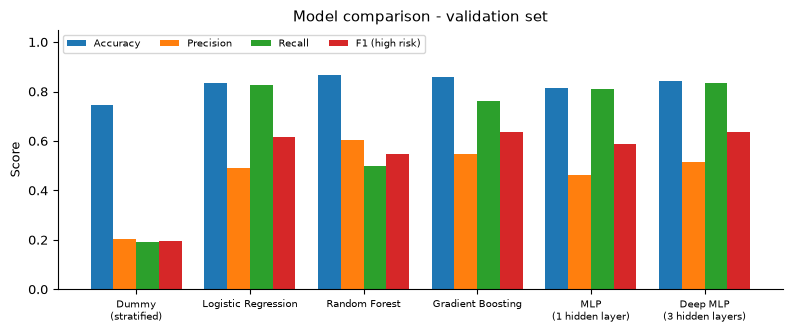

                            train_f1     f1    gap
model                                             
Dummy (stratified)             0.123  0.196 -0.073
Logistic Regression            0.577  0.617 -0.040
Random Forest                  0.904  0.547  0.357
Gradient Boosting              0.717  0.636  0.080
MLP (1 hidden layer)           0.582  0.589 -0.007
Deep MLP (3 hidden layers)     0.667  0.637  0.031
MLP (1 hidden layer) stopped at epoch 47
Deep MLP (3 hidden layers) stopped at epoch 46


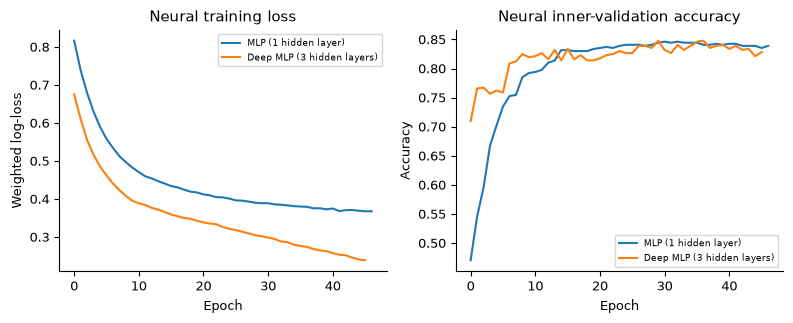

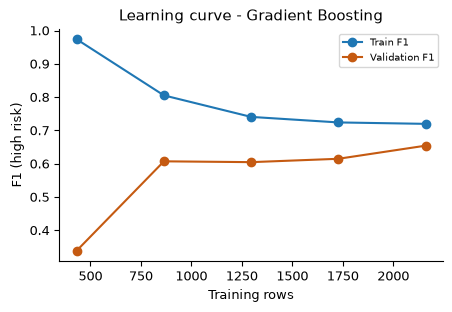

In [14]:
# Q4.3 model comparison chart
fig, ax = plt.subplots(figsize=(8, 3.4)); x = np.arange(len(V)); w = .2
for i, (k, l) in enumerate([('acc', 'Accuracy'), ('prec', 'Precision'), ('rec', 'Recall'), ('f1', 'F1 (high risk)')]): ax.bar(x + (i-1.5)*w, V[k], w, label=l)
ax.set_xticks(x); ax.set_xticklabels([s.replace(' (', '\n(') for s in V.index], fontsize=7); ax.set(ylabel='Score', ylim=(0, 1.05), title='Model comparison - validation set'); ax.legend(fontsize=7, ncol=4, loc='upper left')
plt.tight_layout(); plt.savefig('figures/f9_compare.png', dpi=180); plt.show()

# Q4.4 overfitting: train vs validation F1, neural curves, learning curve
V['gap'] = V.train_f1 - V.f1; print(V[['train_f1', 'f1', 'gap']].round(3))
fig, ax = plt.subplots(1, 2, figsize=(8, 3.3))
for n in ['MLP (1 hidden layer)', 'Deep MLP (3 hidden layers)']:
    m = fitted[n].named_steps['m']; ax[0].plot(m.loss_curve_, label=n); ax[1].plot(m.validation_scores_, label=n); print(n, 'stopped at epoch', m.n_iter_)
ax[0].set(xlabel='Epoch', ylabel='Weighted log-loss', title='Neural training loss'); ax[0].legend(fontsize=6.5)
ax[1].set(xlabel='Epoch', ylabel='Accuracy', title='Neural inner-validation accuracy'); ax[1].legend(fontsize=6.5)
plt.tight_layout(); plt.savefig('figures/f10_nn.png', dpi=180); plt.show()

fr = [.2, .4, .6, .8, 1.0]; lt, lv, sz = [], [], []
for f in fr:
    k = int(len(tr)*f); t1 = tr.sort_values('period_index').iloc[:k]; p = fit_model(champ, models[champ], t1[FEATS], t1.y)
    lt.append(f1_score(t1.y, p.predict(t1[FEATS]))); lv.append(f1_score(yva, p.predict(Xva))); sz.append(k)
fig, ax = plt.subplots(figsize=(4.6, 3.2)); ax.plot(sz, lt, marker='o', label='Train F1'); ax.plot(sz, lv, marker='o', color=ORG, label='Validation F1')
ax.set(xlabel='Training rows', ylabel='F1 (high risk)', title=f'Learning curve - {champ}'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('figures/f11_lc.png', dpi=180); plt.show()

## 5. Hyperparameter optimisation (Q5)
Grid search over the champion only, scored by F1 (high risk) on expanding-window folds drawn from the **training** periods. The test set is never used.

In [17]:
BEST_MODEL = GradientBoostingClassifier  # champion family
def build_gb(params, num=NUM, cat=CAT, oversampling=True, data=None):
    X, y = data
    if oversampling: X, y = oversample(X, y)
    return Pipeline([('pre', make_pre(num, cat)), ('m', GradientBoostingClassifier(random_state=SEED, **params))]).fit(X[num + cat], y)

grid = dict(n_estimators=[100, 200, 300], learning_rate=[0.03, 0.05, 0.1], max_depth=[2, 3, 4], subsample=[0.7, 1.0])
res = []
for vals in itertools.product(*grid.values()):
    prm = dict(zip(grid, vals)); sc = []
    for a, b in folds:
        t1 = tr[tr.period_index <= a]; t2 = tr[(tr.period_index > a) & (tr.period_index <= b)]
        sc.append(f1_score(t2.y, build_gb(prm, data=(t1, t1.y)).predict(t2[FEATS])))
    res.append({**prm, 'cv_f1': np.mean(sc), 'cv_sd': np.std(sc)})
G = pd.DataFrame(res).sort_values('cv_f1', ascending=False).reset_index(drop=True)
best = {k: (int(v) if k in ('n_estimators', 'max_depth') else float(v)) for k, v in G.loc[0, list(grid)].items()}
print('Combinations searched:', len(G), '| best:', best); G.head(5).round(4)

Combinations searched: 54 | best: {'n_estimators': 300, 'learning_rate': 0.03, 'max_depth': 4, 'subsample': 0.7}


,n_estimators,learning_rate,max_depth,subsample,cv_f1,cv_sd
0,300,0.03,4,0.7,0.6988,0.0842
1,300,0.03,4,1.0,0.6852,0.0811
2,300,0.05,4,0.7,0.6846,0.0912
3,200,0.05,4,0.7,0.6825,0.0775
4,300,0.05,3,0.7,0.6812,0.0647


In [18]:
def evaluate(p, d, num=NUM, cat=CAT):
    prob = p.predict_proba(d[num + cat])[:, 1]; return metrics(d.y, (prob >= .5).astype(int), prob)
p_before = build_gb({}, data=(tr, tr.y)); p_after = build_gb(best, data=(tr, tr.y))
pd.DataFrame({'before tuning': evaluate(p_before, va), 'after tuning': evaluate(p_after, va)}).round(3)   # validation only

,before tuning,after tuning
acc,0.858,0.868
prec,0.545,0.580
rec,0.764,0.691
f1,0.636,0.631
macro_f1,0.774,0.775
roc_auc,0.896,0.890
pr_auc,0.688,0.661


## 6. Ablation study and McNemar test (Q6)
Ablations use the validation set; split, seed, hyper-parameters and protocol are fixed.

                                 f1    rec  roc_auc  delta_f1
Full model (reference)        0.631  0.691    0.890     0.000
A1 Remove complaints          0.420  0.427    0.754    -0.211
A2 Remove prior outages       0.633  0.682    0.889     0.002
A3 Remove hydraulic group     0.642  0.709    0.882     0.011
A4 Remove age/pressure ratio  0.636  0.682    0.897     0.005
A5 Remove region              0.630  0.682    0.892    -0.000
A6 Remove weather             0.648  0.745    0.887     0.018
A7 Remove oversampling        0.557  0.491    0.886    -0.074


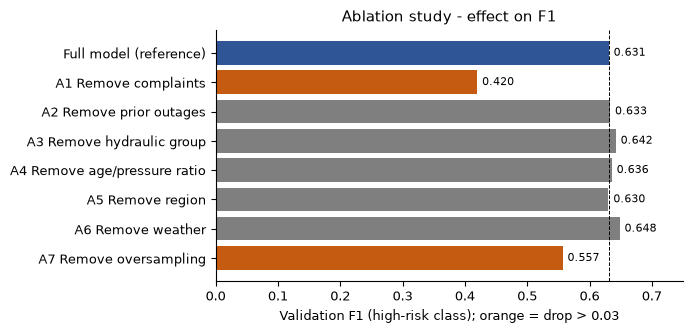

Validation ROC-AUC WITH leakage columns: 1.000  (meaningless in practice)


In [21]:
abl = {}
def run(label, num=NUM, cat=CAT, oversampling=True):
    abl[label] = evaluate(build_gb(best, num, cat, oversampling, data=(tr, tr.y)), va, num, cat)
run('Full model (reference)')
run('A1 Remove complaints', num=[c for c in NUM if c != 'recent_complaints'])
run('A2 Remove prior outages', num=[c for c in NUM if c != 'prior_outages_last_3_periods'])
run('A3 Remove hydraulic group', num=[c for c in NUM if c not in ('avg_pressure_kpa', 'reservoir_distance_km', 'elevation_m', 'age_x_lowpressure')])
run('A4 Remove age/pressure ratio', num=[c for c in NUM if c != 'age_x_lowpressure'])
run('A5 Remove region', cat=['pipe_material'])
run('A6 Remove weather', num=[c for c in NUM if c not in ('rainfall_mm', 'max_temp_c')])
run('A7 Remove oversampling', oversampling=False)
A = pd.DataFrame(abl).T[['f1', 'rec', 'roc_auc']]; A['delta_f1'] = A.f1 - A.loc['Full model (reference)', 'f1']; print(A.round(3))

base_f1 = A.loc['Full model (reference)', 'f1']
fig, ax = plt.subplots(figsize=(7, 3.4)); cols_ = [BLUE] + [ORG if v < base_f1 - .03 else '#7F7F7F' for v in A.f1[1:]]
ax.barh(A.index[::-1], A.f1[::-1], color=cols_[::-1]); ax.axvline(base_f1, color='k', lw=.7, ls='--'); ax.set_xlim(0, .75)
for i, v in enumerate(A.f1[::-1]): ax.text(v+.008, i, f'{v:.3f}', va='center', fontsize=8)
ax.set(xlabel='Validation F1 (high-risk class); orange = drop > 0.03', title='Ablation study - effect on F1'); plt.tight_layout()
plt.savefig('figures/f12_abl.png', dpi=180); plt.show()

# Why leakage columns are excluded (demonstration only)
LK = NUM + ['repair_cost_zar', 'emergency_dispatches']
pl = Pipeline([('pre', make_pre(LK, CAT)), ('m', GradientBoostingClassifier(random_state=SEED))]).fit(tr[LK + CAT], tr.y)
print('Validation ROC-AUC WITH leakage columns: %.3f  (meaningless in practice)' % roc_auc_score(va.y, pl.predict_proba(va[LK + CAT])[:, 1]))

## 7. Final locked evaluation, McNemar test, fairness and saved pipeline (Q5.3, Q6.2, Q8)
The tuned champion and the strongest comparator (Logistic Regression) are refitted on train + validation and scored **once** on the test set.

In [22]:
tv = pd.concat([tr, va])
champ_final = build_gb(best, data=(tv, tv.y))
lr_final = Pipeline([('pre', make_pre()), ('m', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]).fit(tv[FEATS], tv.y)
dummy_final = Pipeline([('pre', make_pre()), ('m', DummyClassifier(strategy='stratified', random_state=SEED))]).fit(tv[FEATS], tv.y)

pc_ = champ_final.predict_proba(Xte)[:, 1]; yc = (pc_ >= .5).astype(int); yl = lr_final.predict(Xte); y = yte.values
print(pd.DataFrame({'Tuned Gradient Boosting': evaluate(champ_final, te), 'Logistic Regression': evaluate(lr_final, te), 'Baseline (Dummy)': evaluate(dummy_final, te)}).round(3))
print('\nTest confusion matrix [[TN FP],[FN TP]]:\n', confusion_matrix(y, yc))
print(classification_report(y, yc, target_names=['low', 'high'], digits=3))

# Bootstrap 95% intervals
rng = np.random.RandomState(SEED); bf, br = [], []
for _ in range(1000):
    i = rng.randint(0, len(y), len(y)); bf.append(f1_score(y[i], yc[i])); br.append(recall_score(y[i], yc[i]))
print('F1 95%% CI: %.3f-%.3f | recall 95%% CI: %.3f-%.3f' % (*np.percentile(bf, [2.5, 97.5]), *np.percentile(br, [2.5, 97.5])))

# McNemar (exact binomial) - same 675 test cases
cc, lc = (yc == y), (yl == y)
b, c = int((cc & ~lc).sum()), int((~cc & lc).sum()); both, neither = int((cc & lc).sum()), int((~cc & ~lc).sum())
p_val = binomtest(min(b, c), b + c, .5).pvalue
print(pd.DataFrame([[both, b], [c, neither]], index=['GB correct', 'GB wrong'], columns=['LR correct', 'LR wrong']))
print('H0: equal error rates | alpha = 0.05 | discordant =', b + c, '| exact p = %.3f ->' % p_val, 'reject H0' if p_val < .05 else 'fail to reject H0')

          Tuned Gradient Boosting  Logistic Regression  Baseline (Dummy)
acc                         0.868                0.850             0.716
prec                        0.582                0.514             0.093
rec                         0.543                0.714             0.095
f1                          0.562                0.598             0.094
macro_f1                    0.742                0.753             0.463
roc_auc                     0.872                0.875             0.463
pr_auc                      0.634                0.622             0.150

Test confusion matrix [[TN FP],[FN TP]]:
 [[529  41]
 [ 48  57]]
              precision    recall  f1-score   support

         low      0.917     0.928     0.922       570
        high      0.582     0.543     0.562       105

    accuracy                          0.868       675
   macro avg      0.749     0.735     0.742       675
weighted avg      0.865     0.868     0.866       675

F1 95% CI: 0.480-0.640 

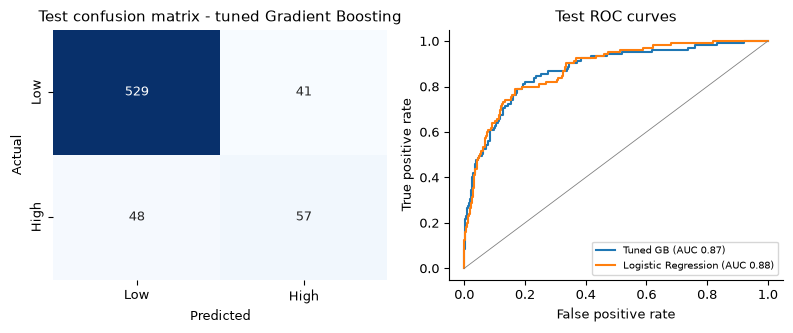

                          rows  actual_high_share  recall  precision  \
informal share <= 11.5%  340.0              0.121   0.488      0.488   
informal share > 11.5%   335.0              0.191   0.578      0.649   

                         false_positive_rate  
informal share <= 11.5%                0.070  
informal share > 11.5%                 0.074  
Mean complaints by informal group (all data):
informal_settlement_pct
False    3.47
True     1.52
Name: recent_complaints, dtype: float64
recent_complaints               0.370
informal_settlement_pct         0.085
avg_pressure_kpa                0.036
pipe_material                   0.033
max_temp_c                      0.003
region                         -0.000
rainfall_mm                    -0.000
prior_outages_last_3_periods   -0.001
age_x_lowpressure              -0.003
pipe_age_years                 -0.003
reservoir_distance_km          -0.008
elevation_m                    -0.013
dtype: float64


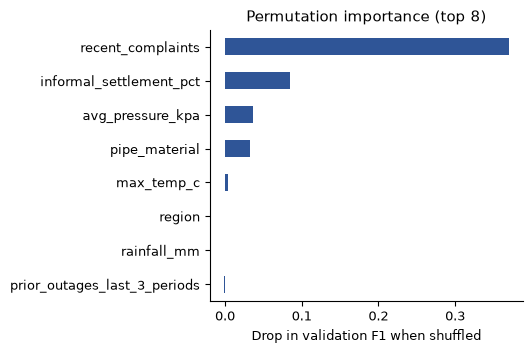

Saved water_outage_pipeline.joblib


In [23]:
# Test figure
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
sns.heatmap(confusion_matrix(y, yc), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0], xticklabels=['Low', 'High'], yticklabels=['Low', 'High'])
ax[0].set(xlabel='Predicted', ylabel='Actual', title='Test confusion matrix - tuned Gradient Boosting')
for n_, pp in [('Tuned GB', pc_), ('Logistic Regression', lr_final.predict_proba(Xte)[:, 1])]:
    f, t_, _ = roc_curve(y, pp); ax[1].plot(f, t_, label=f'{n_} (AUC {roc_auc_score(y, pp):.2f})')
ax[1].plot([0, 1], [0, 1], color='grey', lw=.6); ax[1].legend(fontsize=7); ax[1].set(xlabel='False positive rate', ylabel='True positive rate', title='Test ROC curves')
plt.tight_layout(); plt.savefig('figures/f13_test.png', dpi=180); plt.show()

# Fairness audit by informal-settlement share (median from training+validation)
med = tv.informal_settlement_pct.median(); t2 = te.copy(); t2['pred'] = yc
fair = {}
for nm, m in [(f'informal share <= {med:.1f}%', t2.informal_settlement_pct <= med), (f'informal share > {med:.1f}%', t2.informal_settlement_pct > med)]:
    d = t2[m]; fair[nm] = dict(rows=len(d), actual_high_share=d.y.mean(), recall=recall_score(d.y, d.pred), precision=precision_score(d.y, d.pred, zero_division=0),
                               false_positive_rate=((d.pred == 1) & (d.y == 0)).sum()/max(1, (d.y == 0).sum()))
print(pd.DataFrame(fair).T.round(3))
print('Mean complaints by informal group (all data):'); print(df.groupby(df.informal_settlement_pct > df.informal_settlement_pct.median()).recent_complaints.mean().round(2))

# Permutation importance (validation, champion trained on training only)
pi = permutation_importance(p_after, va[FEATS], va.y, scoring='f1', n_repeats=10, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values(ascending=False); print(imp.round(3))
fig, ax = plt.subplots(figsize=(5.4, 3.6)); imp.head(8)[::-1].plot.barh(color=BLUE, ax=ax)
ax.set(xlabel='Drop in validation F1 when shuffled', title='Permutation importance (top 8)'); plt.tight_layout(); plt.savefig('figures/f14_imp.png', dpi=180); plt.show()

# Save the deployable pipeline (imputation + scaling + encoding + model)
joblib.dump(champ_final, 'water_outage_pipeline.joblib'); print('Saved water_outage_pipeline.joblib')

## 8. User interface (Q7)
The two cells below write `pipeline_utils.py` and `app.py`. Launch with `pip install streamlit` then `streamlit run app.py`.

In [24]:
%%writefile pipeline_utils.py
"""Shared logic for the Johannesburg Water Outage Early-Warning tool."""
import joblib, pandas as pd, numpy as np
from pathlib import Path

MODEL_PATH = Path(__file__).parent / "water_outage_pipeline.joblib"
MATERIALS = ["PVC", "Cast iron", "Asbestos cement", "Steel"]
REGIONS = list("ABCDEFG")
# (min, max, label) – ranges taken from the cleaned training data
LIMITS = {
    "pipe_age_years": (0, 100, "Pipe age (years)"),
    "avg_pressure_kpa": (0, 900, "Average pressure (kPa)"),
    "reservoir_distance_km": (0, 30, "Distance to reservoir (km)"),
    "elevation_m": (1300, 2000, "Elevation (m)"),
    "recent_complaints": (0, 50, "Complaint tickets (last period)"),
    "rainfall_mm": (0, 150, "Rainfall (mm)"),
    "max_temp_c": (-5, 45, "Max temperature (°C)"),
    "informal_settlement_pct": (0, 100, "Informal settlement (%)"),
    "prior_outages_last_3_periods": (0, 3, "Outages in previous 3 periods"),
}
NUM = list(LIMITS) + ["age_x_lowpressure"]
CAT = ["pipe_material", "region"]
THRESHOLD = 0.5

def load_model():
    return joblib.load(MODEL_PATH)

def validate(row: dict):
    """Return a list of plain-language error messages (empty list = valid)."""
    errors = []
    for k, (lo, hi, label) in LIMITS.items():
        v = row.get(k)
        if v is None or (isinstance(v, float) and np.isnan(v)):
            errors.append(f"{label} is required.")
            continue
        try:
            v = float(v)
        except (TypeError, ValueError):
            errors.append(f"{label} must be a number.")
            continue
        if not (lo <= v <= hi):
            errors.append(f"{label} must be between {lo} and {hi} (you entered {v}).")
    if row.get("pipe_material") not in MATERIALS:
        errors.append(f"Pipe material must be one of: {', '.join(MATERIALS)}.")
    if row.get("region") not in REGIONS:
        errors.append(f"Region must be one of: {', '.join(REGIONS)}.")
    return errors

def to_frame(rows):
    d = pd.DataFrame(rows)
    d["age_x_lowpressure"] = d.pipe_age_years / (d.avg_pressure_kpa.fillna(350).clip(lower=50) / 100)
    return d[NUM + CAT]

def explain(row, prob):
    """Brief, plain-language reasons based on the model's strongest drivers."""
    r = []
    if row["recent_complaints"] >= 5: r.append("a high number of recent complaint tickets")
    if row["avg_pressure_kpa"] < 300: r.append("low average water pressure")
    if row["prior_outages_last_3_periods"] >= 1: r.append("recent outage history")
    if row["pipe_material"] in ("Cast iron", "Asbestos cement"): r.append(f"{row['pipe_material'].lower()} pipes (higher failure rates in this data)")
    if row["pipe_age_years"] >= 45: r.append("old pipes")
    label = "HIGH risk" if prob >= THRESHOLD else "LOW risk"
    if r: return f"{label}. Main factors present: " + ", ".join(r) + "."
    return f"{label}. No strong risk factors were present in the values entered."

def predict(model, rows):
    """rows: list of dicts. Returns list of (label, probability, explanation) or raises ValueError."""
    for row in rows:
        errs = validate(row)
        if errs: raise ValueError(" ".join(errs))
    X = to_frame(rows)
    p = model.predict_proba(X)[:, 1]
    return [("High" if pi >= THRESHOLD else "Low", float(pi), explain(r, pi)) for r, pi in zip(rows, p)]

Writing pipeline_utils.py


In [25]:
%%writefile app.py
"""Streamlit interface – run with:  streamlit run app.py"""
import streamlit as st, pandas as pd
from pipeline_utils import *

st.set_page_config(page_title="Johannesburg Water Outage Early Warning", page_icon="💧", layout="wide")
st.title("💧 Johannesburg Water Outage Early-Warning Tool")
st.caption("Predicts whether a ward is HIGH or LOW risk of a major outage (> 12 hours) in the next two-week period.")
with st.expander("Responsible-use notice (please read)", expanded=True):
    st.markdown("- Decision-support only: a human maintenance planner must review every flag.\n"
                "- Trained on **synthetic** ward-level data; recall on unseen periods was ~61%, so some high-risk wards will be missed.\n"
                "- Do **not** use to withhold services from any community, or for individual households.\n"
                "- No personal data is collected or stored.")

@st.cache_resource
def get_model(): return load_model()
model = get_model()
tab1, tab2 = st.tabs(["Single ward", "Upload CSV (batch)"])

with tab1:
    c1, c2, c3 = st.columns(3)
    row = {}
    with c1:
        row["pipe_age_years"] = st.number_input("Pipe age (years)", 0.0, 100.0, 35.0, help="Average pipe age in the ward")
        row["pipe_material"] = st.selectbox("Main pipe material", MATERIALS)
        row["region"] = st.selectbox("Region", REGIONS)
    with c2:
        row["avg_pressure_kpa"] = st.number_input("Average pressure (kPa)", 0.0, 900.0, 360.0, help="Typical distribution-node pressure")
        row["reservoir_distance_km"] = st.number_input("Distance to reservoir (km)", 0.0, 30.0, 5.0)
        row["elevation_m"] = st.number_input("Elevation (m)", 1300.0, 2000.0, 1650.0)
    with c3:
        row["recent_complaints"] = st.number_input("Complaint tickets (last period)", 0, 50, 2)
        row["prior_outages_last_3_periods"] = st.number_input("Outages in previous 3 periods", 0, 3, 0)
        row["rainfall_mm"] = st.number_input("Rainfall (mm)", 0.0, 150.0, 10.0)
        row["max_temp_c"] = st.number_input("Max temperature (°C)", -5.0, 45.0, 22.0)
        row["informal_settlement_pct"] = st.number_input("Informal settlement (%)", 0.0, 100.0, 15.0)
    if st.button("Predict outage risk", type="primary"):
        try:
            label, prob, why = predict(model, [row])[0]
            (st.error if label == "High" else st.success)(f"Predicted class: **{label} risk**  |  Probability of high risk: **{prob:.0%}**")
            st.progress(min(prob, 1.0)); st.write(why)
        except ValueError as e:
            st.warning(f"Please fix the input: {e}")

with tab2:
    st.write("Upload a CSV with columns: " + ", ".join(list(LIMITS) + CAT))
    f = st.file_uploader("CSV file", type="csv")
    if f is not None:
        try:
            d = pd.read_csv(f)
            missing = [c for c in list(LIMITS) + CAT if c not in d.columns]
            if missing: st.error(f"Missing columns: {', '.join(missing)}")
            else:
                out = predict(model, d[list(LIMITS) + CAT].to_dict("records"))
                d["predicted_risk"] = [o[0] for o in out]; d["probability_high"] = [round(o[1], 3) for o in out]
                st.dataframe(d); st.bar_chart(d.predicted_risk.value_counts())
                st.download_button("Download predictions", d.to_csv(index=False), "predictions.csv")
        except ValueError as e: st.warning(str(e))
        except Exception: st.error("Could not read this file. Check that it is a valid CSV.")

Writing app.py


In [ ]:
# Demonstration: 3 valid cases + 1 invalid case through the saved pipeline
import importlib, pipeline_utils1; importlib.reload(pipeline_utils1)
from pipeline_utils1 import load_model, predict
m = load_model()
base_case = dict(pipe_age_years=12, pipe_material='PVC', region='A', avg_pressure_kpa=420, reservoir_distance_km=3, elevation_m=1680,
                 recent_complaints=0, prior_outages_last_3_periods=0, rainfall_mm=5, max_temp_c=21, informal_settlement_pct=4)
cases = {'Valid 1 - newer PVC': base_case,
         'Valid 2 - old cast iron': dict(pipe_age_years=55, pipe_material='Cast iron', region='D', avg_pressure_kpa=180, reservoir_distance_km=9, elevation_m=1600,
                                         recent_complaints=9, prior_outages_last_3_periods=2, rainfall_mm=30, max_temp_c=28, informal_settlement_pct=35),
         'Valid 3 - prior outage': dict(pipe_age_years=38, pipe_material='Steel', region='C', avg_pressure_kpa=310, reservoir_distance_km=6, elevation_m=1640,
                                        recent_complaints=4, prior_outages_last_3_periods=1, rainfall_mm=12, max_temp_c=24, informal_settlement_pct=20)}
for k, v in cases.items():
    lab, prob, why = predict(m, [v])[0]; print(f'{k}: {lab} risk, p(high)={prob:.2f} | {why}')
try: predict(m, [{**base_case, 'pipe_age_years': -5, 'avg_pressure_kpa': 999, 'pipe_material': 'Wood'}])
except ValueError as e: print('Invalid case rejected ->', e)

Valid 1 - newer PVC: Low risk, p(high)=0.02 | LOW risk. No strong risk factors were present in the values entered.
Valid 2 - old cast iron: High risk, p(high)=0.97 | HIGH risk. Main factors present: a high number of recent complaint tickets, low average water pressure, recent outage history, cast iron pipes (higher failure rates in this data), old pipes.
Valid 3 - prior outage: High risk, p(high)=0.95 | HIGH risk. Main factors present: recent outage history.
Invalid case rejected -> Pipe age (years) must be between 0 and 100 (you entered -5.0). Average pressure (kPa) must be between 0 and 900 (you entered 999.0). Pipe material must be one of: PVC, Cast iron, Asbestos cement, Steel.


## Notes for submission
* Replace the synthetic data, re-run all cells and update every table and figure in the report.
* Fill in the **[TEAM INPUT]** items in the report (names, licence/source link, lecturer approval of the deep tabular MLP, screenshots, contribution statement).
* Environment used: Python 3.12, scikit-learn 1.8, pandas 3.0, CPU only, seed 42.